# Quantifying if we're capturing internal variability

Re-estimating the reanalysis variance calculation using MC draws across subsets of runs 

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import zarr
import warnings
from tqdm.notebook import tqdm
from dask.diagnostics import ProgressBar

import matplotlib as mpl
from matplotlib import pyplot as plt
from cartopy import crs as ccrs
import cmocean


import distributed

from funcs_support import get_filepaths,get_params,utility_save
from funcs_readregs import coeffs_mortality, coeffs_gdppc
from funcs_processing import calc_uncerts
from funcs_plot import plot_map

dir_list = get_params()
dir_list['aux_bigmem'] = '/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/'

In [2]:
from distributed import Client

# Start dask client 
# (playing around with workers, threads for efficiency)
client = Client(n_workers=6,
    threads_per_worker=3,
    processes=True,
    memory_limit="8GB")
display(client)

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/climate/proxy/8787/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/climate/proxy/8787/status,Workers: 6
Total threads: 18,Total memory: 44.70 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:36699,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/climate/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:32869,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/climate/proxy/33497/status,Memory: 7.45 GiB
Nanny: tcp://127.0.0.1:36945,


2026-03-19 12:23:07,518 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle cf1ab57818f6fe98de490c0c48a3a41d initialized by task ('rechunk-merge-rechunk-transfer-7d15482adaee50c058f8d5ed70d789b4', 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 46, 0) executed on worker tcp://127.0.0.1:43561
2026-03-19 12:23:30,504 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle cf1ab57818f6fe98de490c0c48a3a41d deactivated due to stimulus 'task-finished-1773944610.2630258'
2026-03-19 12:24:03,657 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle cf1ab57818f6fe98de490c0c48a3a41d initialized by task ('rechunk-merge-rechunk-transfer-7d15482adaee50c058f8d5ed70d789b4', 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 46, 0) executed on worker tcp://127.0.0.1:33645
2026-03-19 12:24:18,743 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle cf1ab57818f6fe98de490c0c48a3a41d deactivated due to stimulus 'task-finished-1773944658.742387'
2026-03-19 12:24:23,795 - distributed.s

In [3]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-region','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','popwght':True},
               'payroll':{'varname':'days90plus','geo_typ':'adm2-us','popwght':True}}

# How many draws of runs for each number of runs
ndraws = 100

# At what gwl to test
gwl = 2

In [4]:
for proc in params_proc:
    #proc = 'mortality'
    
    output_fn = f'{dir_list['aux_bigmem']}obsvar_boot_estimates_{proc}.zarr'
    if not os.path.exists(output_fn+'/.done'):
        #---------------------------
        # Setup
        #---------------------------
        # Load impacts projections
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}*.zarr'))
        def load_impact(fn):
            ds_tmp = xr.open_zarr(fn,consolidated=False)
            ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
            ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
        
            # With a generic run counter
            ds_tmp['exprun'] = (('idv'),np.arange(0,ds_tmp.sizes['idv']))
            ds_tmp = ds_tmp.reset_index('idv')
            ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
            return ds_tmp
        
        with warnings.catch_warnings():
            # Silence zarr warnings related to the /.done flags used
            warnings.filterwarnings('ignore')
            dss = xr.concat([load_impact(fn) for fn in fns],
                        dim='idv',join='outer')
        
        
        dss = dss.chunk({'poly_idx':500,'idv':-1,'proj_base':-1,'gwl':-1})
        dss = dss.sel(gwl=gwl)
        
        # Load max gwls 
        maxgwl = dss.maxgwl.load()
        # Figure out how many BCD-ME members reach a given GWL
        gwl_counter = dss.maxgwl.load().reset_index('idv').groupby(['model','maxgwl']).count()
        gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
        #print(gwl_counter)
        
        # Unstack into model x run array for convenience
        dss = dss.unstack('idv')['d'+proc]
        # Make sure it's still chunked to allow for uncertainty calculations along
        # run dimensions
        dss = dss.chunk({'model':-1,'exprun':-1})
        
        #---------------------------
        # Load 
        #---------------------------
        
        obsvar_estimates_all = []
        tmp_fns = []
        for mod in tqdm(dss.model.values):
            
            obsvar_estimates = []
        
            # Figure out how many runs are available for a particular model
            avail_runs = maxgwl.where(maxgwl>2).sel(model=mod).dropna('exprun').exprun
            max_nruns = avail_runs.max()
            
            for nruns in np.arange(2,max_nruns+1):
                # Bootstrap draws (currently with replacement)
                run_ids = np.random.randint(0,avail_runs.max(),size=(nruns,ndraws))
                run_ids = xr.DataArray(run_ids,
                                       dims = ['nrun','draw'])
        
                # Get variance across runs
                with warnings.catch_warnings():
                    warnings.filterwarnings('ignore')
                    obsvar_tmp = dss.sel(model=mod,exprun=run_ids).mean('proj_base').var('nrun')
                obsvar_tmp = obsvar_tmp.expand_dims({'nruns':[nruns]})
            
                obsvar_estimates.append(obsvar_tmp)
            obsvar_estimates = xr.concat(obsvar_estimates,dim='nruns').to_dataset(name='obsunc')
            # Separate out the mean of the last 5 nruns for reference
            obsvar_estimates['obsunc_last5'] = obsvar_estimates['obsunc'].isel(nruns = slice(-5,None)).mean(['nruns','draw'])
            # Store max number of runs for each model
            obsvar_estimates['max_nruns'] = max_nruns

            tmp_fn = re.sub(r'\.zarr',f'_{mod}_tmp.zarr',output_fn)
            utility_save(obsvar_estimates.drop_encoding(),tmp_fn,zarr_mode='w')
            obsvar_estimates = xr.open_zarr(tmp_fn)
            tmp_fns.append(tmp_fn)
        
            obsvar_estimates_all.append(obsvar_estimates)
        
        # Concatenate into single dataset
        obsvar_estimates_all = xr.concat(obsvar_estimates_all,dim='model',join='outer')
    
        obsvar_estimates_all.attrs = {'SOURCE':'4c_capturing_uncertainty.ipynb',
                                      'DESCRIPTION':(f'Internal variability in projections of {proc} at GWL{str(gwl)}, '+
                                                     f'calculated as the the variance across ensemble members of means across reanalyses for each model, '+
                                                     f'using {str(ndraws)} of #`nruns` bootstrap resampled (with replacement) ensemble members.')}
        # Rechunk for processing below
        obsvar_estimates_all = obsvar_estimates_all.chunk({'draw':-1,'nruns':-1,'model':1,'poly_idx':10})
        utility_save(obsvar_estimates_all.drop_encoding(),output_fn)
        for fn in tmp_fns:
            os.system('rm -rf '+fn)
    else:
        print(output_fn+' exists!')

  0%|          | 0/12 [00:00<?, ?it/s]

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_mortality_ACCESS-ESM1-5_tmp.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/glade/u/home/schwarzwald

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_mortality_ACCESS-ESM1-5_tmp.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


...

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_mortality_MPI-ESM1-2-LR_tmp.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_mortality_MRI-ESM2-0_tmp.zarr saved!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/core.py:5189: PerformanceWarning: Increasing number of chunks by factor of 49
  result = blockwise(
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/core.py:5189: PerformanceWarning: Increasing number of chunks by factor of 49
  result = blockwise(
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/core.py:5189: PerformanceWarning: Increasing number of chunks by factor of 49
  result = blockwise(
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/core.py:5189: PerformanceWarning: Increasing number of chunks by factor of 49
  result = blockwise(
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/dask/array/core.py:5189: PerformanceWarning: Increasing number of chunks by factor of 49
  result = blockwise(
/glade/u/home/schwarzwald/.conda/envs/im

ValueError: Specified Zarr chunks encoding['chunks']=(500,) for variable named 'locid' would overlap multiple Dask chunks. Please check the Dask chunks at position 1 and 2, on axis 0, they are overlapped on the same Zarr chunk in the region slice(None, None, None). Writing this array in parallel with Dask could lead to corrupted data. To resolve this issue, consider one of the following options: - Rechunk the array using `chunk()`. - Modify or delete `encoding['chunks']`. - Set `safe_chunks=False`. - Enable automatic chunks alignment with `align_chunks=True`.

In [ ]:
# Map of how many runs it takes to get to X% of final average internal variability in like CanESM5 / EC-Earth3, with 
# a couple of insets showing the full distributional development across models 

In [9]:
utility_save(obsvar_estimates_all.drop_encoding(),output_fn,zarr_mode='w')

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_mortality.zarr removed to allow overwrite!


/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=13, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/glade/u/home/schwarzwald

/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/obsvar_boot_estimates_mortality.zarr saved!


In [13]:
levels = 20
cmap = cmocean.cm.amp(np.arange(0,1,1/levels))

fig = plt.figure(figsize=(15,5*len(params_proc)))
gs = plt.GridSpec(nrows=2*len(params_proc),ncols=4)


for row_idx,proc in enumerate(params_proc):
    
    # Load shapefile and process centroids
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore')
        # Occasional shapefile fixing warnings
        
        # Load shapefile
        gdf = gpd.read_file(f'{dir_list['aux']}geo_data/{params_proc[proc]['geo_typ']}.shp')
        gdf['geometry'] = gdf.make_valid()
        
        # Remove antarctica, if present
        if 'ISO' in gdf.columns:
            gdf = gdf.query('ISO != "ATA"')
        
        centroids = gdf.geometry.to_crs('EPSG:4326').centroid

    # Load uncertainty estimates
    unc_fn = f'{dir_list['aux_bigmem']}obsvar_boot_estimates_{proc}.nc'
    obsvar_estimates_all = xr.open_dataset(unc_fn)

    # Calculate obsvar estimates normalized to that of last 5 nruns mean
    ratio_to_final_obsunc = obsvar_estimates_all.obsunc.mean('draw') / obsvar_estimates_all.obsunc_last5
    obsvar_estimates_all_norm = obsvar_estimates_all['obsunc'] / obsvar_estimates_all['obsunc_last5']

    # Prep for geogrpahic plotting
    ratio_to_final_obsunc = ratio_to_final_obsunc.set_index({'poly_idx':'locid'})
    
    #--------------------------------
    # Map ---------------------------
    #--------------------------------
    ax_map = fig.add_subplot(gs[(row_idx*2):(row_idx*2+2),0:3],projection=ccrs.PlateCarree())
    plot_data = (ratio_to_final_obsunc>0.9).argmax('nruns').sel(model='CanESM5').sel(poly_idx = gdf.hierid.values)
    
    fig,ax_map=plot_map(plot_data,
             gdf,vmin=0,vmax=levels,cmap=cmocean.cm.amp,
             fig=fig,ax=ax_map)
    #ax_map.coastlines(lw=0.5)
    gpd.GeoSeries(data = gdf.union_all()).plot(facecolor='none',edgecolor='k',linewidth=0.25,ax=ax_map)
    ax_map.set_title('Number of CanESM5 runs needed to on average reach 90% of final internal variability')
    
    ax_map.annotate(proc.title(),(0.025,0.95),xycoords='axes fraction',va='top',
                    fontweight='bold',fontsize=12,
                    bbox={'boxstyle':'round','fc':'w','ec':'w','alpha':0.8})
    
    
    # Inset histogram
    nruns_needed = (ratio_to_final_obsunc>0.9).argmax('nruns')
    ax = ax_map.inset_axes([0.02, 0.2, 0.25, 0.25], xticks=[], yticks=[])
    nruns_needed = (ratio_to_final_obsunc>0.9).argmax('nruns')
    
    N, bins, patches = nruns_needed.plot.hist(bins=np.arange(0,nruns_needed.max()+1),ax=ax)
    
    for binid, patch in enumerate(patches):
        patch.set_facecolor(cmap[binid,:])
    
    for side in ['top','left','right']:
        ax.spines[side].set_visible(False)
    ax.set_xticks(np.arange(1,levels+1,2))
    ax.set_xlim(1,levels)
    ax.set_yticks([])
    ax.set_xlabel('Number of runs needed to reach\n90% of max internal variability')
    ax.set_ylabel('')
    ax.set_title('')
    
    
    #--------------------------------
    # Sample plots ------------------
    #--------------------------------
    
    reg_idxs = {'max':plot_data.argmax(),
                'min':plot_data.argmin()}
    
    for plt_idx,reg_typ in enumerate(reg_idxs):
    
        centroid = centroids[reg_idxs[reg_typ].values]
    
        sp = {'poly_idx':reg_idxs[reg_typ]}
        
        colors = {'CanESM5':'tab:blue',
                  'MIROC6':'tab:red',
                  'EC-Earth3':'tab:purple'}
        
        ax = fig.add_subplot(gs[row_idx*2+plt_idx,3])
        
        for mod,color in colors.items():
            ratio_to_final_obsunc.sel(model=mod).isel(**sp).plot(color=color,label=mod)
            ax.fill_between(obsvar_estimates_all_norm.nruns,
                            obsvar_estimates_all_norm.sel(model=mod).isel(**sp).quantile(0.025,'draw'),
                            obsvar_estimates_all_norm.sel(model=mod).isel(**sp).quantile(0.975,'draw'),
                            color=color,alpha=0.1)
            
            ax.axvline((ratio_to_final_obsunc.nruns.isel(nruns=(ratio_to_final_obsunc.sel(model=mod).isel(**sp)>0.9).argmax().values).values),
                   color=color,linestyle=':')
        
        
        ax.axhline(1,color='k',linestyle='-',lw=0.2)
        ax.axhline(0.9,color='k',linestyle=':')
    
        
        if plt_idx == 0:
            ax.legend(fontsize=7,loc='lower right')
            ax.set_xlabel('')
        else:
            ax.set_xlabel('Number of runs')
        ax.set_title('')
        ax.annotate('Reg. with '+reg_typ+' runs needed',(0.05,0.95),xycoords='axes fraction',va='top',
                    bbox={'boxstyle':'round','fc':'w','ec':'w','alpha':0.8})
        ax.set_ylim([0.25,4])
        ax.set_yticks([0.25,0.5,0.75,0.9,1,1.5,2,4])
        ax.set_yscale('log')
        ax.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
    
        # add connection to main map
        con = mpl.patches.ConnectionPatch(
            xyA=(centroid.x, centroid.y), coordsA=ax_map.transData,   # map location (lon/lat)
            xyB=(0.0, 0.5), coordsB=ax.transAxes,       # left-center of subplot
            axesA=ax_map,
            axesB=ax,
            color='black',
            lw=0.5
        )
        
        fig.add_artist(con)


AttributeError: 'Dataset' object has no attribute 'obsunc_last5'

<Figure size 1500x1000 with 0 Axes>

In [14]:
obsvar_estimates_all

<xarray.Dataset> Size: 20GB
Dimensions:  (model: 12, nruns: 84, poly_idx: 24378, draw: 100)
Dimensions without coordinates: model, nruns, poly_idx, draw
Data variables:
    obsunc   (model, nruns, poly_idx, draw) float64 20GB 6.928 0.01716 ... 0.0
Attributes:
    SOURCE:       4c_capturing_uncertainty.ipynb
    DESCRIPTION:  Internal variability, calculated as the the variance across...

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


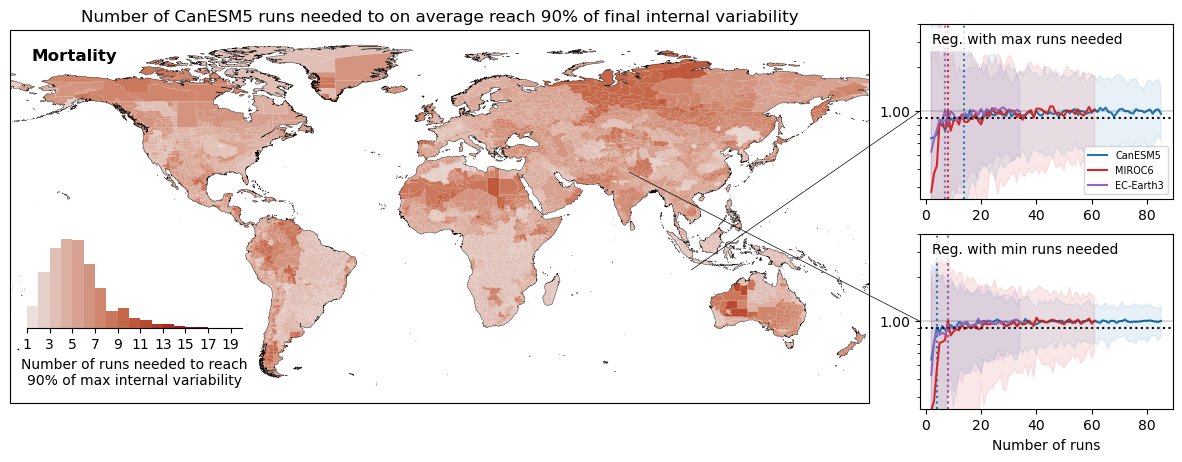

0    MULTIPOLYGON (((-176.223 -44.224, -176.162 -44...
dtype: geometry

In [92]:
obsvar_estimates_all_norm = obsvar_estimates_all['obsunc'] / obsvar_estimates_all['obsunc_last5']

In [158]:
mpl.patches.FancyBboxPatch(

Init signature:
mpl.patches.FancyBboxPatch(
    xy,
    width,
    height,
    boxstyle='round',
    *,
    mutation_scale=1,
    mutation_aspect=1,
    **kwargs,
)
Docstring:     
A fancy box around a rectangle with lower left at *xy* = (*x*, *y*)
with specified width and height.

`.FancyBboxPatch` is similar to `.Rectangle`, but it draws a fancy box
around the rectangle. The transformation of the rectangle box to the
fancy box is delegated to the style classes defined in `.BoxStyle`.
Init docstring:
Parameters
----------
xy : (float, float)
  The lower left corner of the box.

width : float
    The width of the box.

height : float
    The height of the box.

boxstyle : str or `~matplotlib.patches.BoxStyle`
    The style of the fancy box. This can either be a `.BoxStyle`
    instance or a string of the style name and optionally comma
    separated attributes (e.g. "Round, pad=0.2"). This string is
    passed to `.BoxStyle` to construct a `.BoxStyle` object. See
    there for a full d

<xarray.DataArray ()> Size: 8B
array(6)
Coordinates:
    poly_idx  int64 8B 3343
    model     <U13 52B 'EC-Earth3'
    gwl       float64 8B 2.0
    locid     StringDType() 16B 'IND.34.565.2218'
    ageset    <U5 20B 'total'
    covar     <U1 4B '1'
    spectype  <U6 24B 'pooled'

In [112]:
gdf.query('hierid == "CXR"').to_crs('EPSG:4326').centroid

/glade/derecho/scratch/schwarzwald/tmp/ipykernel_122116/2703708411.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  gdf.query('hierid == "CXR"').to_crs('EPSG:4326').centroid


2817    POINT (105.63355 -10.47636)
dtype: geometry

In [104]:
obsvar_estimates_all_norm.sel(model=mod).isel(**sp).locid

<xarray.DataArray 'locid' ()> Size: 16B
array('CXR', dtype=StringDType())
Coordinates:
    poly_idx  int64 8B 2817
    model     <U13 52B 'EC-Earth3'
    gwl       float64 8B 2.0
    locid     StringDType() 16B 'CXR'
    ageset    <U5 20B 'total'
    covar     <U1 4B '1'
    spectype  <U6 24B 'pooled'